# TP PCA — la presentación, explicada

Este notebook es el **respaldo de la presentación de 5 minutos** del TP de PCA (`Guía_PCA.pdf`, entrega el viernes 23/10/2026). Cada sección corresponde a una slide y desarrolla lo que en la slide entra en dos renglones. Además, responde una por una las observaciones que le hicimos a la primera versión del deck.

La teoría completa (derivación con Lagrange, Eckart–Young, ridge) está en `books/explained/cap14_5_pca_componentes_principales.ipynb`. Acá se cita por sección y no se repite. El dataset es `src/datasets/paises_europa.csv`, que trae los mismos 28 países y las mismas 7 variables que el `europe.csv` de la guía.

| Actividad de la guía | Slide | Sección acá | Observación que responde |
|---|---|---|---|
| 1. Idea central y relación con la variabilidad | 2 | §1 | obs. 1 |
| 2. Implementar PCA con SVD | 3 | §2 | obs. 2 y 7 |
| 3. Comparar con scikit-learn | 4 | §3 | obs. 3 y 7 |
| 3. Elegir cuántas componentes | 5 | §4 | obs. 4 |
| 3. Interpretación gráfica | 6 | §5 | obs. 5 |
| 4. Incorporar otro país | 7 | §6 | obs. 6 |
| — | todas | §7 | qué cambia en el deck |

Notación: $\mathbf{Z}$ es la matriz de datos **estandarizada** ($N=28$ filas = países, $p=7$ columnas = variables), $\mathbf{Z}=\mathbf{U}\mathbf{D}\mathbf{V}^T$ su SVD *thin*, $v_j$ la columna $j$ de $\mathbf{V}$ y $d_j$ el valor singular $j$.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "figure.dpi": 110,
    "font.size": 11,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "legend.frameon": False,
})
np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.precision", 3)

paises = pd.read_csv("../../src/datasets/paises_europa.csv", index_col="Country")
X_raw = paises.to_numpy(dtype=float)
N, p = X_raw.shape
print(f"N = {N} países, p = {p} variables")
paises.describe().T[["mean", "std", "min", "max"]]

N = 28 países, p = 7 variables


,mean,std,min,max
Area,166422.536,165538.676,2586.00,603550.00
GDP,31860.714,14502.116,7200.00,80600.00
Inflation,3.343,1.398,0.20,8.00
Life.expect,78.123,3.189,68.74,81.86
Military,1.606,0.801,0.00,4.30
Pop.growth,0.117,0.502,-0.80,1.14
Unemployment,9.921,4.678,2.80,21.70


Las columnas viven en escalas que no tienen nada que ver: `Area` va de 2.586 a 603.550 km² y `Pop.growth` de −0,8 a 1,14. Por eso trabajamos estandarizado (cap. 14.5, §3: sin estandarizar, `Area` sola se lleva el PC1 porque su varianza es millones de veces la de las otras).

In [2]:
mu = X_raw.mean(0)
sd = X_raw.std(0)          # ddof=0: divide por N (lo discutimos en el §3)
Z = (X_raw - mu) / sd      # cada columna con media 0 y varianza 1
print("medias :", Z.mean(0).round(12))
print("varianzas (divisor N):", Z.var(0))

medias : [ 0. -0. -0. -0. -0. -0. -0.]
varianzas (divisor N): [1. 1. 1. 1. 1. 1. 1.]


## 1. Cómo se relaciona la variabilidad con las componentes (slide 2)

📕 ESL §14.5.1 · 📓 cap14_5 §2, Paso 1 (Pitágoras) y Paso 4

> **Observación 1.** La slide decía "con la SVD, la varianza del componente $j$ es $d_j^2/N$". Eso es un **resultado**, pero no contesta la pregunta de la guía: *por qué* la variabilidad tiene algo que ver con las componentes. La respuesta está en el Pitágoras del libro, y de paso conecta con la idea anterior (PC = la recta/plano que mejor aproxima la nube).

#### La idea en criollo

Cada país es una flecha que sale del centro de la nube (los datos están centrados). Cuando lo proyectás sobre el plano de las componentes, esa flecha se parte en dos pedazos perpendiculares: **lo que el plano ve** y **lo que se pierde**. Pitágoras dice que los cuadrados suman. Si sumás eso sobre todos los países y dividís por $N$, cada término se convierte en una varianza, porque con datos centrados "promedio de cuadrados" *es* varianza.

#### Formalizándolo

Para un país $z_i$ (fila de $\mathbf{Z}$, centrada) y el plano $\mathbf{V}_q$ con proyección $H_q=\mathbf{V}_q\mathbf{V}_q^T$:

$$\|z_i\|^2=\underbrace{\|\mathbf{V}_q^Tz_i\|^2}_{\text{coordenadas en el plano}}+\underbrace{\|z_i-H_qz_i\|^2}_{\text{lo que se pierde}} .$$

Promediamos sobre los $N$ países:

$$\underbrace{\frac1N\sum_i\|z_i\|^2}_{\text{varianza total}}=\underbrace{\sum_{j\le q}\frac1N\sum_i(z_i^Tv_j)^2}_{\text{varianza de los PC que conservo}}+\underbrace{\frac1N\sum_i\|z_i-H_qz_i\|^2}_{\text{error medio de reconstrucción}} .$$

Por qué cada término es una varianza:

- **Izquierda.** $\frac1N\sum_i\|z_i\|^2=\sum_k\frac1N\sum_iz_{ik}^2=\sum_k\operatorname{Var}(z_k)$, porque cada columna tiene media 0. Con datos estandarizados cada varianza vale 1, así que el total vale **$p=7$**. Es un número fijo: depende de los datos, no del plano que elijamos.
- **Primer término de la derecha.** $s_{ij}=z_i^Tv_j$ es la coordenada (*score*) del país $i$ en el PC $j$. Los scores también tienen media 0, así que $\frac1N\sum_is_{ij}^2$ es la varianza del PC $j$.

Como el total no se mueve, **maximizar la varianza que conservo es exactamente lo mismo que minimizar lo que pierdo**. Esa es la relación entre variabilidad y componentes: las componentes son los ejes que se quedan con la mayor parte posible de la varianza total, y lo que no se quedan es el error de la aproximación.

La SVD dice cómo se reparte el total entre los ejes: $\frac1N\|\mathbf{Z}v_j\|^2=d_j^2/N$ (cap14_5 §2, Paso 4). Entonces $\sum_jd_j^2/N=7$ y con $q$ componentes el error medio es $\sum_{j>q}d_j^2/N$.

In [3]:
U, d, Vt = np.linalg.svd(Z, full_matrices=False)
V = Vt.T
total = (Z ** 2).sum() / N
filas = []
for q in range(p + 1):
    Vq = V[:, :q]
    conservado = ((Z @ Vq) ** 2).sum() / N              # varianza de los q scores
    perdido = ((Z - Z @ Vq @ Vq.T) ** 2).sum() / N      # error medio de reconstrucción
    filas.append([q, total, conservado, perdido, (d[:q] ** 2).sum() / N])
pd.DataFrame(filas, columns=["q", "total", "conservado", "perdido", "Σ_{j≤q} d²/N"]).set_index("q")

,total,conservado,perdido,Σ_{j≤q} d²/N
q,,,,
0,7.0,0.000,7.000e+00,0.000
1,7.0,3.227,3.773e+00,3.227
2,7.0,4.414,2.586e+00,4.414
3,7.0,5.477,1.523e+00,5.477
4,7.0,6.248,7.522e-01,6.248
5,7.0,6.706,2.943e-01,6.706
6,7.0,6.874,1.256e-01,6.874
7,7.0,7.000,2.477e-30,7.000


**Qué mirar.** La columna `total` vale 7 en todas las filas, y en cada fila `conservado + perdido = 7`. Con $q=2$ se conservan 4,41 de 7 (el 63 %) y la aproximación pierde 2,59. La última columna muestra que lo conservado es la suma de los primeros $d_j^2/N$.

**Texto propuesto para la slide 2** (más o menos lo mismo de largo que el anterior):

> Para cada país, Pitágoras: ‖país‖² = ‖lo que ve el plano‖² + ‖lo que se pierde‖². Promediando sobre los 28 (datos centrados), eso dice: **varianza total (= 7) = varianza de los PC que conservo + error de reconstrucción**. El total es fijo, así que retener más varianza es aproximar mejor. La SVD reparte ese total: el PC *j* se lleva $d_j^2/N$.

#### ⚠️ Confusión típica

- **"Varianza" del PC ≠ "importancia" del PC.** PCA nunca vio una variable respuesta; un eje con poca varianza puede ser el que importa para otra pregunta.
- **Olvidarse de centrar.** Sin centrar, $\frac1N\sum\|z_i\|^2$ no es varianza (incluye la media al cuadrado) y el PC1 apunta hacia el promedio de la nube en vez de a lo largo de ella.

## 2. La implementación, con el signo a la vista (slide 3)

📕 ESL §14.5.1 · 📓 cap14_5 §4

> **Observación 2.** `fijar_signo` era un paso "mágico": se llamaba pero no estaba en la slide.
> **Observación 7.** La función dividía por $N-1$ "para coincidir con sklearn", y después la slide de cierre decía que la diferencia con sklearn era justamente el $N-1$. Contradicción.

#### Por qué hay que fijar el signo (y sí, tu lectura es correcta)

Si $v$ es unitario y maximiza la varianza, $-v$ también: es unitario y $(-v)^T\mathbf{Z}^T\mathbf{Z}(-v)=v^T\mathbf{Z}^T\mathbf{Z}v$. Es **la misma recta** recorrida al revés. En la SVD el cambio se compensa solo: si damos vuelta $v_j$ y también $u_j$,

$$\mathbf{Z}=\sum_jd_j\,u_jv_j^T=\sum_jd_j\,(-u_j)(-v_j)^T ,$$

así que la factorización sigue siendo válida. La matemática no elige el signo; lo elige el detalle interno de la rutina de LAPACK que corre por debajo de `np.linalg.svd`. Hace falta fijarlo para dos cosas:

1. **Comparar** con sklearn: sin una convención común, `np.allclose` falla aunque las dos implementaciones estén bien.
2. **Interpretar de forma reproducible:** "el lado positivo del PC1 es el de los países ricos" tiene que seguir siendo cierto si corremos el código en otra máquina.

La convención que usa sklearn (≥ 1.5, función `svd_flip` con `u_based_decision=False`) es: **en cada dirección, la entrada de mayor valor absoluto queda positiva.** La escribimos explícitamente, en tres líneas, adentro de la función.

#### Qué divisor usamos

Para resolver la contradicción de la observación 7, la función sigue **al libro**: varianza del PC $j$ $=d_j^2/N$, la misma definición del §1. La diferencia con sklearn aparece en el §3, donde se explica de dónde sale y se ve que es un factor exacto $N/(N-1)$.

In [4]:
def pca_svd(X):
    # 1) estandarizar: cada columna con media 0 y varianza 1
    Z = (X - X.mean(0)) / X.std(0)    # std de numpy: divisor N (la de pandas usa N-1)
    # 2) SVD: las direcciones son las columnas de V
    U, d, Vt = np.linalg.svd(Z, full_matrices=False)
    V = Vt.T
    # 3) signo: en cada columna de V, la entrada de mayor |valor| queda positiva
    fila_max = np.abs(V).argmax(axis=0)                  # una fila por columna
    signos = np.sign(V[fila_max, np.arange(V.shape[1])])  # ±1 por columna
    V = V * signos                                        # v_j → ±v_j (la misma recta)
    # 4) scores y varianza de cada componente (divisor N, como ESL)
    scores = Z @ V
    var = d ** 2 / len(X)
    return V, scores, var

V_own, S_own, var_own = pca_svd(X_raw)
print("varianza de cada PC :", var_own.round(3))
print("suma                :", var_own.sum().round(3), " (= p = 7)")

varianza de cada PC : [3.227 1.187 1.063 0.77  0.458 0.169 0.126]
suma                : 7.0  (= p = 7)


Verificamos lo que dijimos del signo: la SVD "cruda" de numpy y la de sklearn no coinciden en el sentido de algunas direcciones, y dar vuelta $u_j$ y $v_j$ juntos no cambia la reconstrucción de $\mathbf{Z}$.

In [5]:
sk = PCA().fit(Z)                                         # mismo input Z
cruda = np.linalg.svd(Z, full_matrices=False)[2].T        # V sin fijar signo
mismo_sentido = np.sign((cruda * sk.components_.T).sum(0)).astype(int)
print("numpy crudo vs sklearn (+1 mismo sentido, -1 opuesto):", mismo_sentido)
print("con nuestro signo                                     :",
      np.sign((V_own * sk.components_.T).sum(0)).astype(int))

U_, d_, Vt_ = np.linalg.svd(Z, full_matrices=False)
U_flip, Vt_flip = U_.copy(), Vt_.copy()
U_flip[:, 0] *= -1; Vt_flip[0] *= -1                      # damos vuelta el PC1 en U y en V
print("Z se reconstruye igual con el PC1 dado vuelta:", np.allclose(U_flip * d_ @ Vt_flip, Z))

numpy crudo vs sklearn (+1 mismo sentido, -1 opuesto): [-1 -1 -1  1  1  1  1]
con nuestro signo                                     : [1 1 1 1 1 1 1]
Z se reconstruye igual con el PC1 dado vuelta: True


**Qué mirar.** Sin la convención, las primeras tres direcciones de numpy apuntan al revés que las de sklearn. Con la convención, coinciden todas. Y la reconstrucción de $\mathbf{Z}$ no cambia al dar vuelta un par $(u_j, v_j)$: el signo es una elección, no un error.

Para la slide alcanza con las líneas 3) de la función (tres renglones) y una frase: *"$v$ y $-v$ son la misma recta; fijamos que el peso más grande sea positivo, como sklearn, para poder comparar."*

## 3. Contra scikit-learn, y por qué divide por $N-1$ (slide 4)

📓 cap14_5 §4 · el resto **(MML / general)**: la corrección de Bessel no está en ESL §14.5

> **Observación 3.** ¿Por qué sklearn divide por $N-1$? ¿Qué es el "7" contra el "7,26"? ¿7 componentes? ¿Una componente puede valer 7,26?

#### Primero, qué es el 7

No son 7 componentes. Es la **varianza total**: la suma de las varianzas de las 7 variables estandarizadas, cada una vale 1, entonces $1\cdot7=7$ (§1). Coincide numéricamente con la cantidad de componentes porque, estandarizado, cada variable aporta exactamente 1. La varianza de **cada** componente es un número real cualquiera (3,23; 1,19; 1,06; …): mide cuánta dispersión hay a lo largo de ese eje, no cuenta nada. Las 7 suman 7 porque se reparten el total sin perder nada.

Con el divisor de sklearn cada una de esas cantidades se multiplica por $N/(N-1)=28/27$, y el total pasa a ser $7\cdot28/27=7{,}26$.

#### Por qué $N-1$: la corrección de Bessel

La pregunta que se hace sklearn es otra. No describe "estos 28 países", sino que trata los datos como una **muestra** de una población y quiere **estimar** la varianza poblacional $\sigma^2$. Para eso, dividir por $N$ subestima en promedio:

$$\sum_i(x_i-\bar x)^2=\sum_i(x_i-\mu)^2-N(\bar x-\mu)^2 .$$

*De dónde sale:* escribí $x_i-\mu=(x_i-\bar x)+(\bar x-\mu)$, elevá al cuadrado y sumá; el término cruzado vale $2(\bar x-\mu)\sum_i(x_i-\bar x)=0$ porque los desvíos a la media suman cero.

Tomando esperanza, $E[(x_i-\mu)^2]=\sigma^2$ y $E[(\bar x-\mu)^2]=\operatorname{Var}(\bar x)=\sigma^2/N$:

$$E\Big[\sum_i(x_i-\bar x)^2\Big]=N\sigma^2-N\cdot\frac{\sigma^2}{N}=(N-1)\,\sigma^2 .$$

Así que para que el estimador no tenga sesgo hay que dividir por $N-1$.

*La intuición, conectada con la clase 1:* la media $\bar x$ es justamente el número $c$ que **minimiza** $\sum_i(x_i-c)^2$ (pérdida cuadrática ⇒ media). Entonces la suma de cuadrados alrededor de $\bar x$ siempre es menor o igual que alrededor de la verdadera $\mu$. Al usar la media de la muestra "nos acercamos de más" a los datos y la dispersión sale chica. Se suele decir que se "gasta un grado de libertad" en estimar la media.

In [6]:
rng = np.random.default_rng(1)
muestras = rng.normal(0, 1, size=(100_000, N))      # 100.000 muestras de 28 datos con σ² = 1
print("promedio de la varianza con divisor N   :", muestras.var(axis=1, ddof=0).mean().round(4),
      f"  (teoría: (N-1)/N = {(N - 1) / N:.4f})")
print("promedio de la varianza con divisor N-1 :", muestras.var(axis=1, ddof=1).mean().round(4), "  (teoría: 1)")

promedio de la varianza con divisor N   : 0.963   (teoría: (N-1)/N = 0.9643)
promedio de la varianza con divisor N-1 : 0.9987   (teoría: 1)


**Para PCA esto es una convención, no un error.** Las direcciones $v_j$, los scores y las **proporciones** de varianza explicada no dependen del divisor (es un factor común que se cancela). Solo cambian los valores absolutos de las varianzas. ESL describe los datos que tiene; sklearn estima. Las dos cosas son razonables.

Dos aclaraciones para no decir de más:

- **Bessel corrige la varianza de cada variable, no los autovalores.** Con $N-1$ cada $\operatorname{Var}(z_k)$ estimada no tiene sesgo, pero los autovalores muestrales siguen sesgados (el más grande tiende a sobreestimar al poblacional, con cualquier divisor). Por eso para PCA el divisor es una convención de escala, no una corrección.
- **De dónde sale el 7,26.** `StandardScaler` divide por $N$ por diseño (es una transformación de los datos, no un estimador) y `PCA` divide por $N-1$. Se mezclan los dos divisores: cada variable queda con varianza 1 según el scaler, pero el PCA la mide como $28/27$. Con el mismo divisor en las dos etapas el total vuelve a ser 7 (lo verificamos abajo).

#### La comparación

In [7]:
Z_sk = StandardScaler().fit_transform(X_raw)
pca_sk = PCA().fit(Z_sk)

comparacion = pd.DataFrame({
    "nuestro": [np.abs(V_own.T - pca_sk.components_).max(),
                np.abs(S_own - pca_sk.transform(Z_sk)).max(),
                np.abs(var_own / var_own.sum() - pca_sk.explained_variance_ratio_).max()],
}, index=["direcciones V (máx |dif|)", "scores Z·V (máx |dif|)", "proporción de varianza (máx |dif|)"])
display(comparacion)

print("varianza sklearn / varianza nuestra, por PC:", (pca_sk.explained_variance_ / var_own).round(6))
print("N/(N-1) =", round(N / (N - 1), 6))
print("total nuestro:", var_own.sum().round(3), "  total sklearn:", pca_sk.explained_variance_.sum().round(3))
Z_ddof1 = (X_raw - X_raw.mean(0)) / X_raw.std(0, ddof=1)    # estandarizar también con N-1
print("total sklearn si se estandariza con N-1:", PCA().fit(Z_ddof1).explained_variance_.sum().round(3))

,nuestro
direcciones V (máx |dif|),1.166e-15
scores Z·V (máx |dif|),6.106e-15
proporción de varianza (máx |dif|),1.665e-16


varianza sklearn / varianza nuestra, por PC: [1.037 1.037 1.037 1.037 1.037 1.037 1.037]
N/(N-1) = 1.037037
total nuestro: 7.0   total sklearn: 7.259
total sklearn si se estandariza con N-1: 7.0


**Qué mirar.** Direcciones, scores y proporciones coinciden hasta $10^{-15}$ (el redondeo de la máquina). Las varianzas difieren en un factor **exacto** $28/27=1{,}037$, el mismo en todas las componentes. Esa es la única diferencia, y viene de una decisión explicada, no de un bug.

**Texto propuesto para la slide 4** (reemplaza la tarjeta "Varianzas × 28/27"):

> **Divisor N−1.** sklearn estima la varianza de la población (corrección de Bessel); nosotros describimos estos 28 países, como ESL. Factor 28/27 en todas: las proporciones no cambian.

## 4. ¿Con cuántas componentes nos quedamos? (slide 5)

📕 ESL §14.5.1 (la comparación con datos aleatorizados del ejemplo de los dígitos) · 📓 cap14_5 §5 · Kaiser y el número de repeticiones son **(MML / general)**

> **Observación 4.** ¿Qué es permutar columnas y para qué? ¿Por qué 300? ¿Qué pasa si no permutamos? ¿Quién es Kaiser?

#### El problema: PCA siempre ordena

PCA ordena las componentes de mayor a menor varianza **siempre**, aunque los datos sean puro ruido. Entonces, "el PC1 retiene el 46 %" no dice nada por sí solo: hace falta saber cuánto retendría el PC1 si **no hubiera ninguna estructura**. Esa es la línea base.

**¿Qué pasa si no hacemos nada?** La referencia ingenua sería: sin correlaciones, cada componente retiene $1/p=14{,}3\,\%$. Pero esa cuenta vale con $N\to\infty$. Con $N=28$, dos variables independientes igual muestran correlaciones muestrales del orden de $1/\sqrt{28}\approx0{,}19$ por azar. PCA las encuentra y las acomoda en el PC1, así que el PC1 de puro ruido retiene bastante más que 14 %. Comparar contra 14 % haría parecer "estructura" cosas que el azar produce solo.

#### Permutar columnas: los mismos datos, sin relaciones

Mezclar al azar el orden de **una columna** no cambia sus valores: misma media, misma varianza, mismos mínimo y máximo. Lo único que rompe es **a qué país pertenece cada valor**. Si mezclamos cada columna por separado, cada variable queda intacta pero las relaciones entre variables (que el GDP alto venga junto con la esperanza de vida alta) desaparecen. El total sigue valiendo 7, así que las proporciones son comparables. Es exactamente "estos datos, si no hubiera estructura".

misma media y varianza por columna: True True


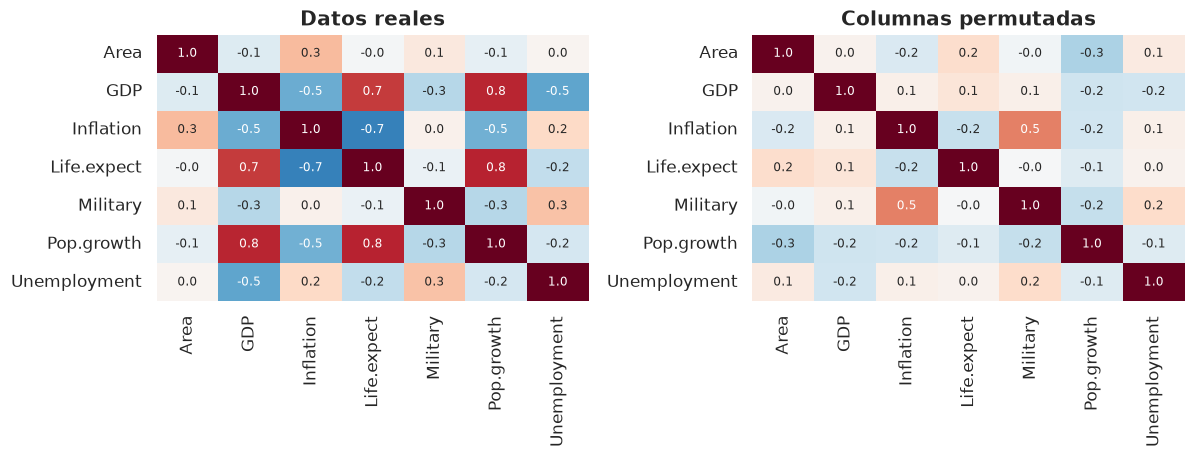

In [8]:
rng = np.random.default_rng(0)
Z_perm = np.column_stack([rng.permutation(Z[:, j]) for j in range(p)])

print("misma media y varianza por columna:", np.allclose(Z_perm.mean(0), Z.mean(0)), np.allclose(Z_perm.var(0), Z.var(0)))
fig, axs = plt.subplots(1, 2, figsize=(11, 4.3))
for ax, M, t in [(axs[0], Z, "Datos reales"), (axs[1], Z_perm, "Columnas permutadas")]:
    sns.heatmap(np.corrcoef(M.T), ax=ax, vmin=-1, vmax=1, cmap="RdBu_r", annot=True, fmt=".1f",
                xticklabels=paises.columns, yticklabels=paises.columns, cbar=False, annot_kws={"size": 8})
    ax.set_title(t)
plt.tight_layout(); plt.show()

**Qué mirar.** A la izquierda hay correlaciones fuertes (GDP con Life.expect, Inflation contra los dos). A la derecha quedan valores chicos y sin patrón: esas son las correlaciones que fabrica el azar con 28 filas, y son las que PCA va a "explicar" en la línea base.

#### ¿Por qué 300 permutaciones?

Cada permutación da una curva distinta, porque el azar es distinto. Lo que queremos es la curva **esperada**, y la estimamos promediando $R$ curvas: es un promedio de Monte Carlo. Su error estándar baja como $1/\sqrt R$. No hay nada especial en 300: alcanza con que el error de la línea base sea mucho más chico que las diferencias que queremos leer (46 % contra ~26 %). Más repeticiones no cambian la conclusión, solo tardan más.

In [9]:
def proporciones_permutadas(R, seed=0):
    rng = np.random.default_rng(seed)
    out = np.empty((R, p))
    for r in range(R):
        Zp = np.column_stack([rng.permutation(Z[:, j]) for j in range(p)])
        d_p = np.linalg.svd(Zp, compute_uv=False)
        out[r] = d_p ** 2 / (d_p ** 2).sum()
    return out

filas = []
for R in [10, 30, 100, 300, 1000, 3000]:
    B = proporciones_permutadas(R)
    filas.append([R, B[:, 0].mean(), B[:, 0].std() / np.sqrt(R)])
pd.DataFrame(filas, columns=["R", "PC1 promedio (ruido)", "error estándar"]).set_index("R")

,PC1 promedio (ruido),error estándar
R,,
10,0.252,5.746e-03
30,0.259,4.129e-03
100,0.255,2.556e-03
300,0.256,1.441e-03
1000,0.256,7.894e-04
3000,0.256,4.603e-04


**Qué mirar.** Desde $R\approx100$ el promedio del PC1 en ruido se estabiliza en ~25,6 % y el error estándar ya es de décimas de punto. Con 300 el error es ≈ 0,14 puntos: muchísimo menos que la distancia al 46 % real. Lo pudimos haber hecho con 1000, y la conclusión sería la misma.

Ahora el gráfico que conviene llevar a la slide: proporciones reales contra la banda del ruido (percentiles 5 y 95 de 3000 permutaciones).

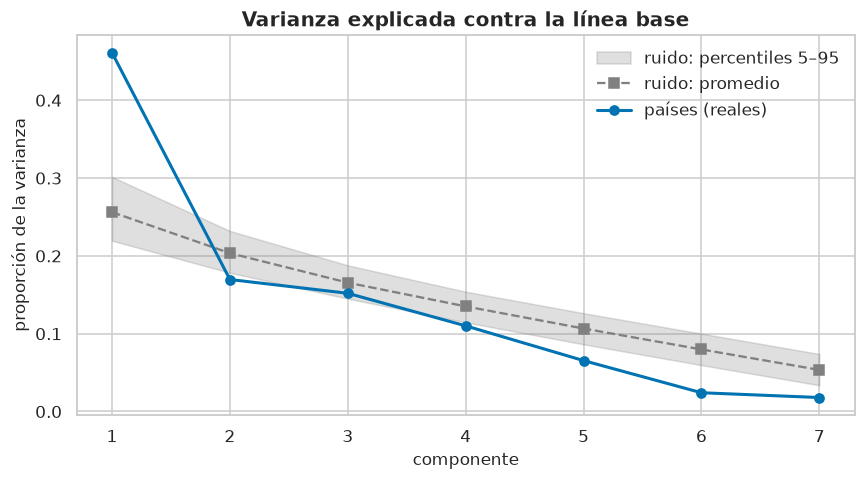

,real,ruido promedio,ruido p95
PC1,0.461,0.256,0.302
PC2,0.170,0.203,0.232
PC3,0.152,0.166,0.188
PC4,0.110,0.135,0.154
PC5,0.065,0.107,0.126
PC6,0.024,0.080,0.100
PC7,0.018,0.053,0.074


In [10]:
B = proporciones_permutadas(3000)
prop = var_own / var_own.sum()
k = np.arange(1, p + 1)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.fill_between(k, np.percentile(B, 5, 0), np.percentile(B, 95, 0), color="gray", alpha=0.25, label="ruido: percentiles 5–95")
ax.plot(k, B.mean(0), "s--", color="gray", label="ruido: promedio")
ax.plot(k, prop, "o-", lw=2, label="países (reales)")
ax.set(xlabel="componente", ylabel="proporción de la varianza", xticks=k, title="Varianza explicada contra la línea base")
ax.legend(); plt.tight_layout(); plt.show()

pd.DataFrame({"real": prop, "ruido promedio": B.mean(0), "ruido p95": np.percentile(B, 95, 0)},
             index=[f"PC{j}" for j in k]).round(3)

**Qué mirar (y esto cambia el discurso de la slide).**

- **PC1 (46 %)** está muy por encima de la banda del ruido (p95 ≈ 30 %). Es estructura real.
- **PC2 (17 %)** queda **dentro** de la banda, incluso por debajo del promedio del ruido (~20 %). Con este criterio, el PC2 **no supera al azar**. La comparación es algo conservadora (cuando el PC1 se lleva mucho, a las demás les queda menos), pero el mensaje honesto es: el PC2 lo usamos para **dibujar** y su interpretación es tentativa.

#### ¿Quién es Kaiser?

No es Franz Beckenbauer ("der Kaiser", el líbero del Bayern Múnich), aunque el apodo era justo eso. Es **Henry F. Kaiser**, un psicómetra estadounidense que en 1960 popularizó la regla: *quedate con las componentes cuyo autovalor de la matriz de correlaciones sea mayor que 1*. La idea: estandarizado, cada variable original aporta varianza 1, así que una componente con $\lambda_j>1$ resume más que una variable suelta.

Lo mencionábamos porque es la regla que más aparece en apuntes y en preguntas de defensa. Aplicada acá, $\lambda=(3{,}23;\,1{,}19;\,1{,}06;\,0{,}77;\dots)$ da **3 componentes**. Pero mirá cuántos autovalores mayores que 1 produce el ruido:

In [11]:
lam_real = var_own                                    # autovalores de la matriz de correlaciones (divisor N)
lam_ruido = B * p                                      # proporción × total (= 7)
print("Kaiser sobre los datos reales  :", (lam_real > 1).sum(), "componentes")
print("Kaiser sobre ruido (promedio)  :", (lam_ruido > 1).sum(1).mean().round(2), "componentes")
print("autovalor más grande del ruido :", lam_ruido[:, 0].mean().round(2), "(promedio)")

Kaiser sobre los datos reales  : 3 componentes
Kaiser sobre ruido (promedio)  : 3.23 componentes
autovalor más grande del ruido : 1.79 (promedio)


**Qué mirar.** Datos **sin ninguna estructura** también dan, en promedio, unos 3 autovalores mayores que 1. Con $N=28$ y $p=7$, Kaiser no distingue estructura de ruido. Por eso no conviene apoyarse en Kaiser y sí en la línea base de permutaciones, que mide exactamente lo que el azar produce con *este* $N$ y *estas* variables. La versión de la línea base que compara autovalores contra los del ruido se llama **análisis paralelo de Horn** (1965) **(general)**.

**Decisión que defendemos:** $q=2$ para el gráfico; PC1 es estructura clara; PC2 es para visualizar, con lectura tentativa; con $q=2$ queda afuera el 37 % de la varianza.

**Texto propuesto para la slide 5** (columna derecha):

> **PC1 supera al azar:** 46 % contra 26 % (el 95 % de las mezclas queda por debajo de 30 %).
> **PC2 no supera al azar** (17 % contra 20 %).
> Usamos 2 componentes para graficar: conservan el 63 % y pierden el **37 %**.

## 5. De dos columnas sin nombre a una interpretación (slide 6)

📕 ESL §14.5.1 · 📓 cap14_5 §5 (loadings y biplot)

> **Observación 5.** Con $q=2$ el dataset pasa a tener dos columnas sin interpretación. ¿Cómo sabemos cuánto pesa cada variable original? ¿Por qué el gráfico mezcla países y variables? Y faltaban los nombres de los ejes.

#### Lo que tenés después de PCA: dos columnas, sí

Es correcto: las nuevas "variables" son las columnas de $\mathbf{Z}\mathbf{V}_2$, una por componente, y no tienen nombre. Pero **no son una caja negra**, porque cada una es una combinación lineal conocida de las originales:

$$s_{i1}=v_{11}\,z_{i,\text{Area}}+v_{21}\,z_{i,\text{GDP}}+\dots+v_{71}\,z_{i,\text{Unemployment}} .$$

Los pesos $v_{k1}$ (los **loadings**, la columna 1 de $\mathbf{V}$) son la receta. Como todas las variables están estandarizadas, los pesos son comparables entre sí: un $|v_{k1}|$ grande quiere decir que la variable $k$ mueve mucho al PC1. Con el ejemplo de Luxemburgo:

In [12]:
scores = pd.DataFrame(S_own[:, :2], index=paises.index, columns=["PC1", "PC2"])
print("Así queda el dataset con q = 2 (primeras filas):")
display(scores.head())

i = paises.index.get_loc("Luxembourg")
receta = pd.DataFrame({"z (estandarizado)": Z[i], "peso v_k1": V_own[:, 0], "aporte z·v": Z[i] * V_own[:, 0]},
                      index=paises.columns)
display(receta.round(2))
print("suma de los aportes =", receta["aporte z·v"].sum().round(3), " = score PC1 de Luxemburgo:", scores.loc["Luxembourg", "PC1"].round(3))

Así queda el dataset con q = 2 (primeras filas):


,PC1,PC2
Country,,
Austria,1.082,-1.270
Belgium,0.681,-0.416
Bulgaria,-2.610,0.270
Croatia,-1.270,1.901
Czech Republic,0.167,-0.132


,z (estandarizado),peso v_k1,aporte z·v
Area,-1.01,-0.12,0.13
GDP,3.42,0.50,1.71
Inflation,0.04,-0.41,-0.02
Life.expect,0.52,0.48,0.25
Military,-0.90,-0.19,0.17
Pop.growth,2.08,0.48,0.99
Unemployment,-0.92,-0.27,0.25


suma de los aportes = 3.478  = score PC1 de Luxemburgo: 3.478


**Qué mirar.** El score de Luxemburgo en el PC1 (≈ 3,5, el más alto) es la suma de 7 aportes. Casi todo sale de su `GDP` (1,7) y su `Pop.growth` (1,0). Así se "abre" una columna sin nombre: mirando qué variables la construyen.

#### Dos formas de medir el peso de una variable en un eje

1. **Loading** $v_{kj}$: cuánto entra la variable $k$ en la receta del PC $j$.
2. **Correlación** entre la variable original $z_k$ y la columna de scores $s_j$. Se puede calcular directamente con `np.corrcoef`, sin saber nada de PCA. Las dos están ligadas por una fórmula (cap14_5 §5): $\operatorname{corr}(z_k,s_j)=v_{kj}\,d_j/\sqrt N$. O sea, la correlación es el loading escalado por el desvío del eje. Lo comprobamos:

corr calculada a mano = fórmula: True


,loading PC1,loading PC2,corr PC1,corr PC2
Area,-0.12,-0.17,-0.22,-0.19
GDP,0.50,-0.13,0.90,-0.14
Inflation,-0.41,-0.37,-0.73,-0.40
Life.expect,0.48,0.27,0.87,0.29
Military,-0.19,0.66,-0.34,0.72
Pop.growth,0.48,0.08,0.85,0.09
Unemployment,-0.27,0.55,-0.49,0.60


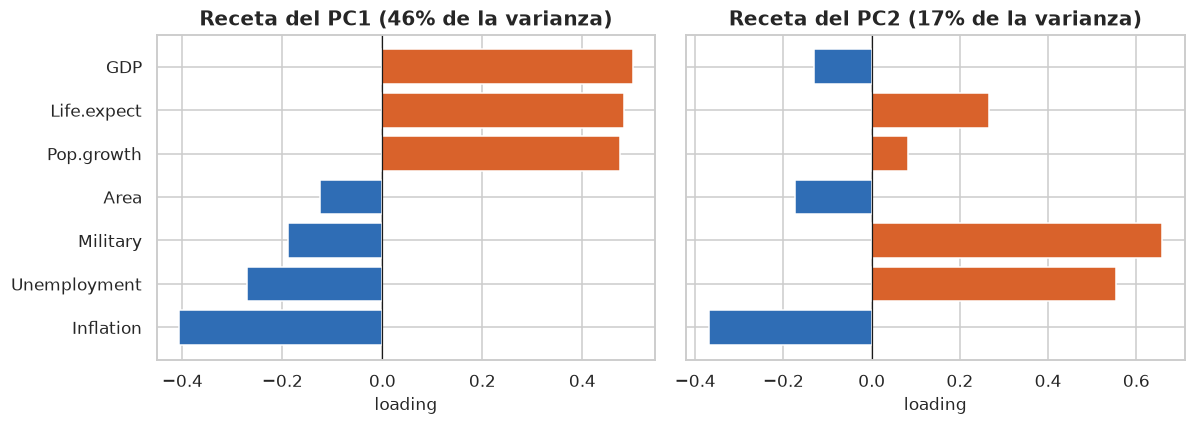

In [13]:
corr_directa = np.array([[np.corrcoef(Z[:, k], S_own[:, j])[0, 1] for j in range(2)] for k in range(p)])
corr_formula = V_own[:, :2] * np.sqrt(var_own[:2])          # v_kj · d_j/√N  (var_own = d²/N)
print("corr calculada a mano = fórmula:", np.allclose(corr_directa, corr_formula))

pesos = pd.DataFrame(np.c_[V_own[:, :2], corr_directa], index=paises.columns,
                     columns=["loading PC1", "loading PC2", "corr PC1", "corr PC2"])
display(pesos.round(2))

fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for j, ax in enumerate(axs):
    orden = pesos[f"loading PC{j+1}"].sort_values()
    ax.barh(orden.index, orden.values, color=np.where(orden.values > 0, "#D9622B", "#2F6DB5"))
    ax.axvline(0, color="k", lw=0.8)
    ax.set(title=f"Receta del PC{j+1} ({prop[j]:.0%} de la varianza)", xlabel="loading")
plt.tight_layout(); plt.show()

**Qué mirar.** El gráfico de barras es la forma más directa de mostrar "qué pesa en cada eje", y para una audiencia que ve la slide 30 segundos es más fácil de leer que un biplot.

- **PC1:** positivo `GDP`, `Life.expect`, `Pop.growth` (≈ +0,5 cada una); negativo `Inflation` (−0,41) y `Unemployment` (−0,27). Lo leemos como un eje de **desarrollo económico**.
- **PC2:** positivo `Military` (+0,66) y `Unemployment` (+0,55); negativo `Inflation` (−0,37). Un eje de "gasto militar y desempleo", con la salvedad del §4: este eje no se distingue del ruido.

#### El biplot: por qué mezcla países y variables

"Bi" porque dibuja **dos cosas distintas en el mismo plano**:

- **Puntos = países** (las filas). Su posición es $(s_{i1},s_{i2})$: sus dos columnas nuevas.
- **Flechas = variables** (las columnas originales). Su punta es $(\operatorname{corr}(z_k,s_1),\ \operatorname{corr}(z_k,s_2))$: cuánto se parece esa variable a cada eje.

Juntos sirven para leer **por qué** un país está donde está: un país que cae del lado al que apunta una flecha tiende a tener un valor alto en esa variable (es una lectura de **dirección**, no de valores: con puntos = scores y flechas = correlaciones, el producto escalar punto·flecha no reproduce el valor de la variable; para que lo haga habría que dibujar los scores divididos por $\sqrt{\lambda_j}$). Las flechas largas son variables bien representadas por el plano, porque su largo² es la fracción de la varianza de esa variable que capturan PC1 y PC2. Como las correlaciones miden a lo sumo 1 y los scores llegan a ±4,6, las flechas se agrandan con un factor visual (acá ×3) que no cambia direcciones ni proporciones.

Los nombres de los ejes salen de la tabla de loadings de arriba, no del gráfico: el gráfico solo los muestra.

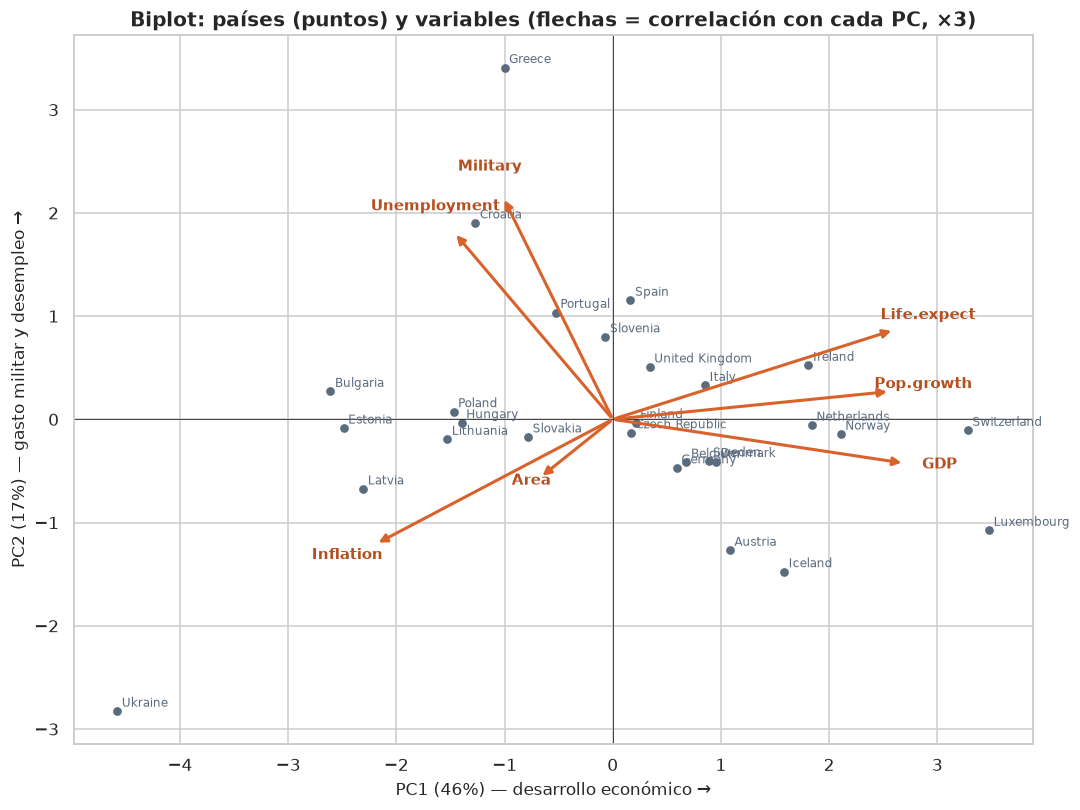

In [14]:
fig, ax = plt.subplots(figsize=(10, 7.5))
ax.scatter(scores["PC1"], scores["PC2"], s=22, color="#5A6B7D", zorder=2)
for nombre, (x_, y_) in scores.iterrows():
    ax.annotate(nombre, (x_, y_), fontsize=8, color="#5A6B7D", xytext=(3, 3), textcoords="offset points")
esc = 3
for k_, var_name in enumerate(paises.columns):
    cx, cy = esc * corr_directa[k_]
    ax.annotate("", xy=(cx, cy), xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="#D9622B", lw=2))
    ax.text(cx * 1.12, cy * 1.12, var_name, color="#B4501F", fontsize=10, fontweight="bold", ha="center")
ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
ax.set(xlabel=f"PC1 ({prop[0]:.0%}) — desarrollo económico →",
       ylabel=f"PC2 ({prop[1]:.0%}) — gasto militar y desempleo →",
       title="Biplot: países (puntos) y variables (flechas = correlación con cada PC, ×3)")
plt.tight_layout(); plt.show()

**Qué mirar.** Hacia la derecha, en la dirección de `GDP`/`Life.expect`/`Pop.growth`, están Luxemburgo, Suiza y Noruega. A la izquierda, del lado de `Inflation`, están Ucrania, Bulgaria y los bálticos. Arriba, en la dirección de `Military`/`Unemployment`, está Grecia. `Area` tiene la flecha más corta: el plano casi no la representa (su varianza vive en otras componentes).

**Propuesta para la slide 6:** reemplazar el biplot por los **dos gráficos de barras de loadings** (se leen en 5 segundos), o dejar el biplot pero con los ejes nombrados como en la figura de arriba. En cualquier caso, decir en voz alta: *"los puntos son países, las flechas son las variables originales; el nombre de cada eje sale de qué variables lo construyen."*

#### ⚠️ Confusión típica

- **Leer distancias del biplot como exactas.** Es una proyección: queda afuera el 37 %. Dos países cercanos en el plano pueden diferir mucho en los otros ejes.
- **Escalar las flechas con la varianza de sklearn** ($N-1$): salen $\sqrt{28/27}$ más largas y ya no son correlaciones (pueden superar 1).

## 6. Incorporar un país: proyectar contra reajustar (slide 7)

📕 ESL §14.5.1 (ec. 14.52, $\hat\lambda_i=\mathbf{V}_q^T(x_i-\bar x)$) · 📓 cap14_5 §6

> **Observación 6.** Explicar qué es proyectar, cómo se hace y qué pasa después. Reajustar es "recalcular como si Rusia estuviera desde el principio".

La guía dice "incorporar al conjunto de datos información sobre otro país". Hay dos maneras de leer eso y conviene mostrar las dos, porque responden preguntas distintas:

| | Proyectar | Reajustar |
|---|---|---|
| Qué se mantiene | $\mu$, $\sigma$ y $\mathbf{V}$ de los 28 | nada: se recalcula todo con 29 |
| Pregunta que responde | ¿dónde cae el país nuevo en **nuestro** mapa? | ¿cambia el mapa si el país es parte de los datos? |
| En sklearn | `scaler.transform` + `pca.transform` | `fit` de nuevo |

**El país.** Rusia, con los valores del **CIA World Factbook en su versión web de entre el 19/11/2012 y enero de 2013**, que es la edición de la que sale `europe.csv`. Se verificó comparando capturas de Wayback Machine: Austria, Alemania, Luxemburgo, España, Ucrania y Grecia coinciden en las 7 columnas, y el GDP de Austria (41.600) solo aparece en esa ventana. La copia más antigua del CSV es de un curso de R de 2013 ([SociallyCompute/info480](https://github.com/SociallyCompute/info480)), y Rusia no está en el archivo original.

Unidades (Factbook): `Area` km² totales; `GDP` per cápita PPP en USD (est. 2011); `Inflation` % de precios al consumidor (est. 2011); `Life.expect` años al nacer (est. 2012); `Military` % del PIB (dato de 2005 para Rusia); `Pop.growth` % anual (est. 2012); `Unemployment` % (est. 2011). Capturas de Rusia: [19/11/2012](https://web.archive.org/web/20121119030838/https://www.cia.gov/library/publications/the-world-factbook/geos/rs.html) y [15/01/2013](https://web.archive.org/web/20130115023754/https://www.cia.gov/library/publications/the-world-factbook/geos/rs.html).

⚠️ `Pop.growth` de Rusia pasó de −0,48 a −0,01 justo en la captura del 19/11/2012. Usamos −0,01 porque es el de la misma edición que el resto, pero conviene mencionarlo si preguntan.

In [15]:
rusia = pd.Series({"Area": 17_098_242, "GDP": 16_700, "Inflation": 8.4, "Life.expect": 66.46,
                   "Military": 3.9, "Pop.growth": -0.01, "Unemployment": 6.6})   # Factbook nov. 2012 – ene. 2013
x_rus = rusia[paises.columns].to_numpy(float)

#### Proyectar, paso a paso

El modelo ya está armado: un centro ($\mu$), una escala ($\sigma$) y dos ejes ($v_1,v_2$), todos calculados con los 28. Proyectar es **usar ese modelo sin tocarlo**:

1. **Estandarizar con la regla de los 28:** $z=(x-\mu)/\sigma$. No con la media de Rusia, ni recalculando con Rusia adentro: si cambiamos la regla, ya no estamos midiendo en el mismo mapa.
2. **Coordenadas en el plano:** $\hat\lambda=\mathbf{V}_2^Tz=(z^Tv_1,\ z^Tv_2)$. Cada coordenada es un producto escalar: "cuánto de $z$ va en la dirección de cada eje". Es la misma receta que usamos para Luxemburgo en el §5.
3. **Qué se pierde:** volvemos a 7 dimensiones con $\hat z=\mathbf{V}_2\hat\lambda$ (el punto del plano más cercano a $z$). El residuo $z-\hat z$ es lo que el plano no ve. Por Pitágoras (§1), $\|z\|^2=\|\hat\lambda\|^2+\|z-\hat z\|^2$, y la fracción $\|z-\hat z\|^2/\|z\|^2$ dice **qué parte del país queda fuera del plano**.

In [16]:
mu28, sd28 = X_raw.mean(0), X_raw.std(0)
z_rus = (x_rus - mu28) / sd28                         # paso 1: regla de los 28
display(pd.DataFrame({"x (crudo)": x_rus, "z (desvíos de la media de los 28)": z_rus}, index=paises.columns).round(2))

lam_rus = V_own[:, :2].T @ z_rus                      # paso 2: coordenadas
z_hat = V_own[:, :2] @ lam_rus                        # paso 3: reconstrucción en 7-D
perdido = ((z_rus - z_hat) ** 2).sum()
print("coordenadas (PC1, PC2):", lam_rus.round(2))
print(f"‖z‖² = {(z_rus ** 2).sum():.0f}   ‖λ‖² = {(lam_rus ** 2).sum():.0f}   perdido = {perdido:.0f}")
print(f"fracción fuera del plano: {perdido / (z_rus ** 2).sum():.0%}")

# mismo resultado con sklearn: transformar con lo ENTRENADO, sin volver a ajustar
sc28 = StandardScaler().fit(X_raw)
pca28 = PCA(n_components=2).fit(sc28.transform(X_raw))
print("igual a sklearn:", np.allclose(lam_rus, pca28.transform(sc28.transform(x_rus[None]))[0]))

perdido28 = (Z ** 2).sum(1) - (S_own[:, :2] ** 2).sum(1)
frac28 = perdido28 / (Z ** 2).sum(1)
print(f"en los 28: perdido máximo {perdido28.max():.1f} ({paises.index[perdido28.argmax()]}); "
      f"fracción mediana {np.median(frac28):.0%}, máxima {frac28.max():.0%} ({paises.index[frac28.argmax()]})")

,x (crudo),z (desvíos de la media de los 28)
Area,1.710e+07,104.16
GDP,1.670e+04,-1.06
Inflation,8.400e+00,3.68
Life.expect,6.646e+01,-3.72
Military,3.900e+00,2.92
Pop.growth,-1.000e-02,-0.26
Unemployment,6.600e+00,-0.72


coordenadas (PC1, PC2): [-17.31 -18.72]
‖z‖² = 10887   ‖λ‖² = 650   perdido = 10237
fracción fuera del plano: 94%
igual a sklearn: True
en los 28: perdido máximo 12.1 (Spain); fracción mediana 37%, máxima 98% (Czech Republic)


**Qué mirar.** El `Area` de Rusia está a **104 desvíos estándar** de la media de los 28: ninguno de los 28 se le acerca. Su $\|z\|^2$ (≈ 10.900) es casi todo `Area`. Como `Area` casi no pesa en PC1 ni PC2 (§5), el plano captura poco de eso: Rusia cae lejísimos, en (−17,3; −18,7), y aun así el **94 %** de su $\|z\|^2$ queda **fuera** del plano. Casi toda su posición también viene de `Area` (aporta −13,0 y −18,0 a las dos coordenadas): el −17,3 en PC1 no quiere decir "muy poco desarrollada", es un efecto de extrapolar.

Hay que leer los dos números juntos. La fracción sola engaña: algún país de los 28 tiene una fracción todavía mayor, pero es un país pegado al centro, con un $\|z\|^2$ chiquito, así que lo que pierde en valor absoluto es casi nada. Rusia, en cambio, pierde unas **10.200 unidades**, unas 850 veces lo que pierde el peor de los 28 (España, 12,1). Esa combinación (mucho en absoluto y casi todo en proporción) es lo que dice que el modelo de los 28 no sabe describir a Rusia: es extrapolar.

#### Reajustar: Rusia como parte de los datos

Ahora agregamos la fila y corremos `pca_svd` de nuevo. Cambian $\mu$ y $\sigma$ (el desvío de `Area` se dispara) y, con eso, los ejes. Para comparar ejes viejos y nuevos usamos $|v_j^Tv_k'|$, el coseno del ángulo entre la dirección vieja $j$ y la nueva $k$ (en valor absoluto, porque el signo es una convención, §2). Comparamos **todos contra todos** y no solo "PC2 contra PC2": si dos ejes se intercambian, la comparación por número de orden lo esconde.

|coseno| entre ejes viejos (filas) y nuevos (columnas):


,PC1 (+R),PC2 (+R),PC3 (+R)
PC1 (28),0.97,0.24,0.08
PC2 (28),0.03,0.45,0.85
PC3 (28),0.22,0.67,0.46


ángulo PC1 viejo–nuevo: 15°
autovalores 28 países: [3.23 1.19 1.06]   29 países: [3.44 1.43 0.95]
proporción de varianza  28 países: [0.461 0.17  0.152]   29 países: [0.492 0.204 0.136]


,PC1 (28),PC2 (28),PC1 (+R),PC2 (+R),PC3 (+R)
Area,-0.12,-0.17,-0.31,0.59,0.22
GDP,0.50,-0.13,0.45,0.37,0.04
Inflation,-0.41,-0.37,-0.44,0.23,-0.16
Life.expect,0.48,0.27,0.49,-0.10,0.25
Military,-0.19,0.66,-0.30,0.16,0.67
Pop.growth,0.48,0.08,0.40,0.31,0.36
Unemployment,-0.27,0.55,-0.16,-0.57,0.53


Area de Rusia reestandarizada con 29: z = 5.28  (máximo posible con N=29 y divisor N: √(N-1) = 5.29); aporta el 96% de la suma de cuadrados de esa columna


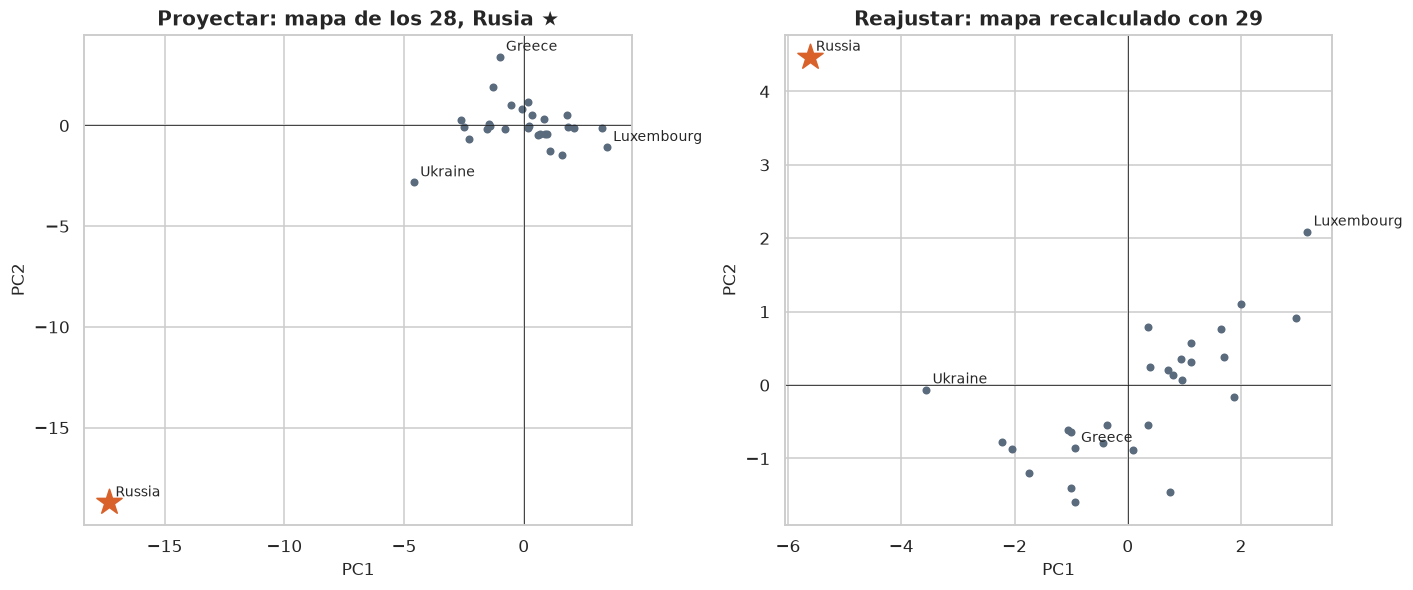

In [17]:
X29 = np.vstack([X_raw, x_rus])
V29, S29, var29 = pca_svd(X29)
prop29 = var29 / var29.sum()

cosenos = pd.DataFrame(np.abs(V_own[:, :3].T @ V29[:, :3]),
                       index=["PC1 (28)", "PC2 (28)", "PC3 (28)"], columns=["PC1 (+R)", "PC2 (+R)", "PC3 (+R)"])
print("|coseno| entre ejes viejos (filas) y nuevos (columnas):")
display(cosenos.round(2))
print("ángulo PC1 viejo–nuevo: %.0f°" % np.degrees(np.arccos(cosenos.iloc[0, 0])))
print("autovalores 28 países:", var_own[:3].round(2), "  29 países:", var29[:3].round(2))
print("proporción de varianza  28 países:", prop[:3].round(3), "  29 países:", prop29[:3].round(3))
display(pd.DataFrame(np.c_[V_own[:, :2], V29[:, :3]], index=paises.columns,
                     columns=["PC1 (28)", "PC2 (28)", "PC1 (+R)", "PC2 (+R)", "PC3 (+R)"]).round(2))

Z29 = (X29 - X29.mean(0)) / X29.std(0)
print(f"Area de Rusia reestandarizada con 29: z = {Z29[-1, 0]:.2f}  "
      f"(máximo posible con N=29 y divisor N: √(N-1) = {np.sqrt(28):.2f}); "
      f"aporta el {Z29[-1, 0] ** 2 / (Z29[:, 0] ** 2).sum():.0%} de la suma de cuadrados de esa columna")

fig, axs = plt.subplots(1, 2, figsize=(13, 5.5))
idx29 = list(paises.index) + ["Russia"]
for ax, Sx, nombres, t in [(axs[0], np.vstack([S_own[:, :2], lam_rus]), idx29, "Proyectar: mapa de los 28, Rusia ★"),
                            (axs[1], S29[:, :2], idx29, "Reajustar: mapa recalculado con 29")]:
    ax.scatter(Sx[:-1, 0], Sx[:-1, 1], s=18, color="#5A6B7D")
    ax.scatter(*Sx[-1], marker="*", s=300, color="#D9622B", zorder=3)
    for n_, (x_, y_) in zip(nombres, Sx):
        if n_ in ("Russia", "Ukraine", "Luxembourg", "Greece"):
            ax.annotate(n_, (x_, y_), fontsize=9, xytext=(4, 4), textcoords="offset points")
    ax.axhline(0, color="k", lw=0.5); ax.axvline(0, color="k", lw=0.5)
    ax.set(title=t, xlabel="PC1", ylabel="PC2")
plt.tight_layout(); plt.show()

**Qué mirar.**

- **PC1 gira 15°** y conserva su lectura de "desarrollo" (GDP, Life.expect, Pop.growth contra Inflation), con algo más de `Area` y `Military`.
- **Los ejes 2 y 3 se intercambian.** El PC2 viejo ("militar y desempleo") coincide en 0,85 con el **PC3 nuevo**: no desaparece, baja un lugar. El **PC2 nuevo** es otro eje: `Area` y `GDP` contra `Unemployment`. Comparando solo "PC2 contra PC2" se ve un giro de ~63° y se pierde que es un intercambio.
- En el panel izquierdo, Rusia aplasta al resto contra el origen; en el derecho, el mapa se reacomoda alrededor de Rusia.

**El mecanismo, con cuidado de no mezclar las dos lecturas.** Los "104 desvíos" son de la regla de los 28, la de **proyectar**, y ahí no se maximiza nada, así que no mueven ningún eje. Al **reajustar**, `Area` se reestandariza con Rusia adentro. Rusia queda en $z\approx5{,}3$, prácticamente el máximo posible con 29 filas, y aporta el 96 % de la suma de cuadrados de esa columna. Así, `Area` deja de medir "superficie" y pasa a ser casi un indicador de "ser Rusia". Esa variable nueva no está correlacionada con las demás de la misma forma que antes, y arma un eje propio.

**Por qué se reordena el eje 2 y no el 1.** Con 28 países, los autovalores eran 3,23, 1,19 y 1,06. $\lambda_2$ y $\lambda_3$ están casi empatados (diferencia 0,12, contra 2,04 entre $\lambda_1$ y $\lambda_2$). Cuando dos autovalores están tan cerca, sus direcciones son inestables: cualquier perturbación los reordena o los mezcla. $\lambda_1$, bien separado, aguanta. Esto se suma a lo del §4 (el PC2 no superaba al azar), pero es otro criterio: el de §4 mira la varianza contra el ruido, y este mira la distancia al autovalor vecino.

**La implicancia, que es lo que pide discutir la guía.** Estandarizar pone a las variables en la misma escala, pero **no protege contra un país extremo**: al reestandarizar, una variable puede pasar a ser "el país raro" y cambiar qué ejes aparecen. Las conclusiones de PCA son de **este** conjunto de datos, y los ejes con autovalores parecidos son los primeros en caerse.

**Texto propuesto para la slide 7** (tarjeta de "Proyectar"):

> **Proyectar: el modelo de los 28, sin tocarlo.** (1) Estandarizar con la media y el desvío de los 28. (2) Multiplicar por $v_1$ y $v_2$: cae en (−17,3; −18,7), casi todo por Area. (3) Fuera del plano queda el 94 % de su $\|z\|^2$: unas 850 veces el error del peor de los 28.

## 7. Qué cambia en la presentación

| Slide | Antes | Después | Por qué |
|---|---|---|---|
| 2 (idea) | "varianza del PC $j$ $=d_j^2/N$" sin justificar | Pitágoras: varianza total (7) = conservada + error de reconstrucción (texto del §1) | obs. 1: conecta "mejor aproximación" con "máxima varianza" |
| 3 (código) | `fijar_signo(...)` sin definir; `var = d²/(N-1)` | las 3 líneas del signo dentro de la función; `var = d²/N` como el libro | obs. 2 y 7 |
| 4 (sklearn) | "varianzas × 28/27" sin motivo; "suman 7,26 y no 7" | factor 28/27 exacto explicado con Bessel; el 7 es la varianza total = 7 variables × varianza 1 | obs. 3 |
| 5 (cuántas) | "permutadas ≈ 26 %", Kaiser, 300 sin explicar | barras reales contra azar; PC1 supera al azar, **PC2 no**; sacar Kaiser de la slide (queda para preguntas) | obs. 4 |
| 6 (biplot) | ejes sin nombre, puntos y flechas sin explicar | barras de loadings o biplot con ejes nombrados + la frase "puntos = países, flechas = variables" | obs. 5 |
| 7 (Rusia) | "proyectar" sin explicar; valores aproximados; "PC2 gira 57°" | los tres pasos; valores verificados del Factbook (nov. 2012 – ene. 2013); los ejes 2 y 3 se intercambian porque $\lambda_2\approx\lambda_3$ | obs. 6 + revisión |
| 8 (cierre) | "difieren solo en signo y en N−1" contra un código que dividía por N−1 | con el signo fijado, la única diferencia con sklearn es el divisor | obs. 7 |

**Preguntas probables en la defensa, con dónde está la respuesta:**

- ¿Por qué estandarizaron? → §0 y cap14_5 §3.
- ¿Por qué su signo coincide con el de sklearn? ¿Y si no coincidiera? → §2.
- ¿Por qué sklearn da otras varianzas? → §3.
- ¿Por qué 2 componentes? ¿Es significativo el PC2? → §4.
- ¿Qué significa una flecha del biplot? → §5.
- ¿Por qué Rusia mueve el PC2 y casi no el PC1? → §4 y §6: el PC2 era débil y `Area` pesaba poco en el PC1; el PC1 es estructura real.